In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd

import shap
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
rf_model = joblib.load("../models/random_forest_model.pkl")

tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

feature_columns = joblib.load(
    "../models/feature_columns.pkl"
)

print("Random Forest loaded successfully!")
print("TF-IDF Vectorizer loaded successfully!")
print("Feature Columns loaded successfully!")

print("\nTotal Features :", len(feature_columns))

Random Forest loaded successfully!
TF-IDF Vectorizer loaded successfully!
Feature Columns loaded successfully!

Total Features : 2030


In [4]:
explainer = shap.TreeExplainer(rf_model)

print("SHAP initialized successfully!")

SHAP initialized successfully!


In [9]:
# ==========================================
# 5. Select a Movie
# ==========================================

movie_index = int(
    input("Enter Movie Index (0-5320): ")
)

print("\nSelected Movie\n")

print(
    model_df.loc[
        movie_index,
        [
            "budget",
            "runtime",
            "franchise",
            "release_year",
            "release_month",
            "roi"
        ]
    ]
)

Enter Movie Index (0-5320):  159



Selected Movie

budget           1.300000e+07
runtime          9.000000e+01
franchise        0.000000e+00
release_year     1.993000e+03
release_month    9.000000e+00
roi             -8.022965e-01
Name: 159, dtype: float64


In [10]:
# ==========================================
# 6. Modify Movie Parameters
# ==========================================

new_budget = float(
    input("\nNew Budget ($): ")
)

new_runtime = float(
    input("New Runtime (minutes): ")
)

new_franchise = int(
    input("Franchise (0 = No, 1 = Yes): ")
)

new_release_year = int(
    input("Release Year: ")
)

new_release_month = int(
    input("Release Month (1-12): ")
)


New Budget ($):  28000000
New Runtime (minutes):  159
Franchise (0 = No, 1 = Yes):  1
Release Year:  2015
Release Month (1-12):  7


In [11]:
# ==========================================
# 7. Create Modified Feature Vector
# ==========================================

movie_features = X_final.iloc[[movie_index]].copy()

movie_features["budget"] = new_budget

movie_features["runtime"] = new_runtime

movie_features["franchise"] = new_franchise

movie_features["release_year"] = new_release_year

movie_features["release_month"] = new_release_month

print("Modified feature vector created successfully!")

print(movie_features.shape)

Modified feature vector created successfully!
(1, 2030)


In [12]:
# ==========================================
# 8. Predict ROI
# ==========================================

predicted_roi = rf_model.predict(movie_features)[0]

original_roi = model_df.loc[
    movie_index,
    "roi"
]

print("\nPrediction Completed!\n")

print(f"Original ROI  : {original_roi:.4f}")

print(f"Predicted ROI : {predicted_roi:.4f}")


Prediction Completed!

Original ROI  : -0.8023
Predicted ROI : 4.2509


In [13]:
# ==========================================
# 9. Investment Recommendation
# ==========================================

def investment_recommendation(roi):

    if roi < 0:

        recommendation = "Do Not Invest"

        risk = "High Risk"

    elif roi < 1:

        recommendation = "Invest with Caution"

        risk = "Medium Risk"

    else:

        recommendation = "Recommended Investment"

        risk = "Low Risk"

    return recommendation, risk


recommendation, risk = investment_recommendation(
    predicted_roi
)

print("=" * 60)

print("INVESTMENT DECISION")

print("=" * 60)

print(f"Original ROI      : {original_roi:.4f}")

print(f"Predicted ROI     : {predicted_roi:.4f}")

print(f"Recommendation    : {recommendation}")

print(f"Risk Level        : {risk}")

INVESTMENT DECISION
Original ROI      : -0.8023
Predicted ROI     : 4.2509
Recommendation    : Recommended Investment
Risk Level        : Low Risk


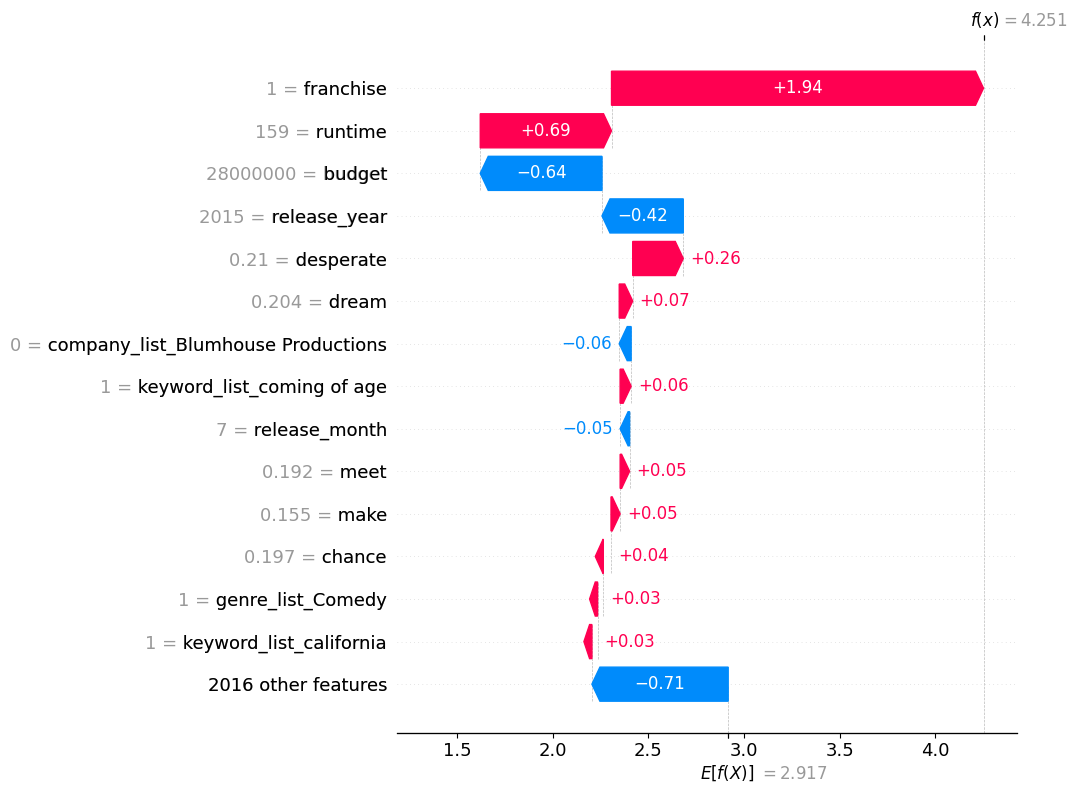

In [14]:
# ==========================================
# 10. SHAP Explanation
# ==========================================

shap_values = explainer(movie_features)

shap.plots.waterfall(
    shap_values[0],
    max_display=15
)

In [16]:
# ==========================================
# 11. Final Decision Summary
# ==========================================

roi_change = predicted_roi - original_roi

print("\n" + "=" * 60)

print("DECISION SUPPORT SUMMARY")

print("=" * 60)

print(f"Movie Index           : {movie_index}")

print(f"Original ROI          : {original_roi:.4f}")

print(f"Modified Predicted ROI: {predicted_roi:.4f}")

print(f"ROI Improvement       : {roi_change:+.4f}")

print(f"Investment Decision   : {recommendation}")

print(f"Risk Level            : {risk}")

print("\nInterpretation:")

if roi_change > 0:

    print(
        f"The modified production strategy improved the "
        f"predicted ROI by {roi_change:.4f}. "
        "The changes are expected to have a positive "
        "impact on investment returns."
    )

elif roi_change < 0:

    print(
        f"The modified production strategy reduced the "
        f"predicted ROI by {abs(roi_change):.4f}. "
        "The proposed changes may negatively affect "
        "investment returns."
    )

else:

    print(
        "The modified production strategy produced "
        "no significant change in the predicted ROI."
    )

print("=" * 60)


DECISION SUPPORT SUMMARY
Movie Index           : 159
Original ROI          : -0.8023
Modified Predicted ROI: 4.2509
ROI Improvement       : +5.0532
Investment Decision   : Recommended Investment
Risk Level            : Low Risk

Interpretation:
The modified production strategy improved the predicted ROI by 5.0532. The changes are expected to have a positive impact on investment returns.


# Conclusion

A Decision Support System (DSS) was developed using the trained Random Forest regression model to assist movie producers in evaluating investment decisions.

The system allows users to modify key production parameters, including budget, runtime, franchise status, release year, and release month, while preserving all other movie characteristics. Based on the modified inputs, the DSS predicts the expected Return on Investment (ROI), compares it with the original ROI, provides an investment recommendation, classifies the associated investment risk, and explains the prediction using SHAP.

This what-if analysis framework enables decision-makers to evaluate alternative production strategies before investing, making the proposed system a practical tool for data-driven decision support in the movie industry.